# Telco churn: XGBoost with Bayesian tuning, and what drives churn (SHAP)

The logistic regression (`02_modeling`) draws a straight line per variable and misses the tenure peak and the handset step. A gradient-boosted tree model learns shapes and interactions on its own. How much does that buy, and which variables drive churn?

Rules (the same as the logistic notebook):
- **Every choice is made on the training set with 5-fold stratified CV**, on the same folds: the trend variables, the hyperparameters, the decision threshold.
- **The hold-out set is scored once**, after every choice is frozen. It estimates performance and selects nothing.
- **SHAP values are computed on the hold-out after it is scored**: they explain the frozen model on customers it has never seen.
- All preprocessing lives inside the sklearn `Pipeline`, fitted on the rows it is trained on, so the pickle carries it.
- `Customer_ID` and `ethnic` are never features. Apart from the two single-customer explanations (no ID), only aggregates are shown.

All the logic lives in `src/churn/` (`model.py`, `plots.py`); this notebook only calls it.

In [1]:
import numpy as np
import optuna
import pandas as pd
from matplotlib import pyplot as plt
from scipy.special import expit
from sklearn.metrics import ConfusionMatrixDisplay

from churn import model, plots
from churn.config import ROOT, load_config
from churn.data import clean, load_raw, split

cfg = load_config()
m, s = cfg["model"], cfg["shap"]
xg, lf = m["xgboost"], m["logistic_final"]
TARGET = cfg["target"]
# Threshold-free metrics decide; precision, recall and F1 come after the threshold is chosen (section 5).
RANKING = ["roc_auc", "pr_auc", "log_loss"]
optuna.logging.set_verbosity(optuna.logging.WARNING)
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

df = clean(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["cleaning"])
train, test = split(df, TARGET, cfg["test_size"], cfg["seed"])
X, y = model.split_xy(train, cfg)
colors = plots.family_colors(list(cfg["families"]))
print(f"training set: {len(X):,} customers, {X.shape[1]} input variables; "
      f"hold-out: {len(test):,} customers, not used until section 6")


def summary(cv: pd.DataFrame) -> pd.Series:
    return cv.agg(["mean", "sem"]).apply(lambda c: f"{c['mean']:.4f} ± {c['sem']:.4f}")


def at_cut(y_true: pd.Series, proba, cut: float) -> pd.Series:
    """Metrics at one probability cut, and the share of customers it flags as churners."""
    return pd.Series({**model.metrics(y_true, proba, cut), "flagged": (proba >= cut).mean()})

C:\Users\matte\Desktop\SDG_churn_tech_test\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


training set: 80,000 customers, 97 input variables; hold-out: 20,000 customers, not used until section 6


## 1. A pipeline for trees
Same cleaning, same seven engineered ratios (3 scale-free, 4 trend: see `02_modeling` section 1) and same categorical encoding as the logistic regression; the numeric side is simpler, because a tree only asks "is the value above this threshold?".

| Step | Logistic regression | XGBoost | Why the difference |
|---|---|---|---|
| Long tails | `arcsinh` (signed log) | none | a split depends only on the order of the values |
| Missing numbers | median + one indicator per missing block | left as NaN | at each split XGBoost learns which branch missing values go to |
| Scaling | `StandardScaler` | none | no penalty on coefficients |
| Categoricals | `Missing` level + one-hot (levels < 0.5% pooled) | the same | one encoding for both models |

## 2. Do the trend variables add information?
Decided **before** the tuning, so that the search runs once, on the final inputs. The model is the XGBoost of the previous version of this notebook (max_depth 4, 757 trees, learning rate 0.05, subsample and colsample 0.8: `model.xgboost.before_tuning`), with and without the four trend ratios, on the same folds: the difference is **paired**.

In [2]:
before = model.xgboost(cfg, **xg["before_tuning"])
cv_without = model.cv_metrics(model.build_tree_pipeline(cfg, before, trend=False), X, y, cfg)
cv_with = model.cv_metrics(model.build_tree_pipeline(cfg, before), X, y, cfg)
pd.DataFrame({"without trend": summary(cv_without[RANKING]), "with trend": summary(cv_with[RANKING]),
              "with − without (paired)": summary((cv_with - cv_without)[RANKING])})

,without trend,with trend,with − without (paired)
roc_auc,0.6964 ± 0.0015,0.7031 ± 0.0016,0.0067 ± 0.0005
pr_auc,0.6820 ± 0.0024,0.6930 ± 0.0026,0.0110 ± 0.0005
log_loss,0.6301 ± 0.0011,0.6251 ± 0.0012,-0.0050 ± 0.0002


**Takeaway: the trend ratios add real information.** +0.0067 ± 0.0005 ROC-AUC (13 paired SE), +0.0110 PR-AUC and −0.0050 ± 0.0002 log-loss (25 SE).
- A tree model gets far more out of them than the logistic regression did (+0.0009). A tree cannot divide two columns, and a drop of 100 minutes means something very different for a light user and for a heavy one. Expressed as a share of the customer's own level, the drop is one split.
- **Decision: they stay** (`features.trend`). It is the largest gain after the choice of model, larger than the tuning below.

## 3. Bayesian optimisation of the hyperparameters
**Optuna** with its TPE sampler (a Bayesian method): after each trial it models which values gave a low loss and which a high one, and proposes the next trial where a low loss is more likely. Unlike a grid, it spends its trials near the good region. Each trial is a **5-fold CV of the whole pipeline**, scored by **log-loss** (the proper scoring rule that also chose C for the logistic regression); the sampler has a fixed seed, so the search is reproducible.

| Hyperparameter | Range | What it controls |
|---|---|---|
| `max_depth` | 3–10 | how many variables one tree can combine (interactions) |
| `min_child_weight` | 1–10 | the smallest leaf: larger = no splits on a handful of customers |
| `learning_rate` | 0.01–0.20 (log scale) | how much each tree corrects the previous ones |
| `n_trees` (`n_estimators`) | 200–1,200 | how many trees |
| `subsample` | 0.6–1.0 | share of customers each tree sees |
| `colsample_bytree` | 0.6–1.0 | share of columns each tree sees |

40 trials (`model.xgboost.n_trials`).

In [3]:
study = model.tune_xgboost(cfg, X, y)
best = study.best_params
print(f"{len(study.trials)} trials; best CV log-loss {study.best_value:.4f} (trial {study.best_trial.number})")
trials = study.trials_dataframe().rename(columns=lambda c: c.removeprefix("params_"))
trials.sort_values("value").head(8)[["number", "value", *xg["search"]]].rename(columns={"value": "cv_log_loss"})

40 trials; best CV log-loss 0.6234 (trial 33)


,number,cv_log_loss,max_depth,min_child_weight,learning_rate,n_trees,subsample,colsample_bytree
33,33,0.6234,8,5.0051,0.0138,913,0.8818,0.6946
38,38,0.6234,8,2.6145,0.0146,1056,0.9187,0.6796
32,32,0.6235,8,4.6788,0.0120,946,0.9054,0.6804
24,24,0.6236,8,1.7592,0.0104,980,0.9286,0.6336
19,19,0.6236,7,4.0237,0.0189,966,0.9043,0.6982
29,29,0.6236,9,2.1668,0.0112,954,0.8969,0.6851
30,30,0.6236,8,3.2418,0.0103,978,0.9300,0.7460
23,23,0.6236,8,1.1368,0.0123,1116,0.9577,0.6814


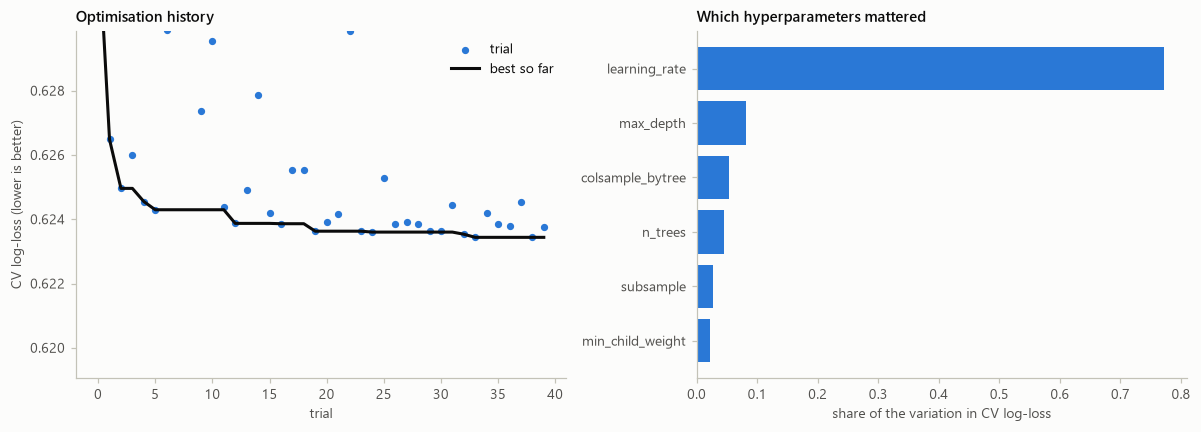

In [4]:
# Left: every trial's CV log-loss and the best so far. Right: how much of the variation in CV log-loss across the
# trials each hyperparameter explains (Optuna's fANOVA importance).
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history = trials.sort_values("number")
axes[0].scatter(history["number"], history["value"], s=14, color=plots.SERIES[0], label="trial")
axes[0].plot(history["number"], history["value"].cummin(), color=plots.INK, linewidth=2, label="best so far")
axes[0].set(xlabel="trial", ylabel="CV log-loss (lower is better)", title="Optimisation history")
axes[0].set_ylim(top=history["value"].quantile(0.9))
axes[0].legend()
fanova = optuna.importance.FanovaImportanceEvaluator(seed=cfg["seed"])
importance = pd.Series(optuna.importance.get_param_importances(study, evaluator=fanova)).iloc[::-1]
axes[1].barh(importance.index, importance.to_numpy(), color=plots.SERIES[0])
axes[1].set(xlabel="share of the variation in CV log-loss", title="Which hyperparameters mattered")
fig.tight_layout()

**Takeaway: the search converges, and the best region is clear.** Best CV log-loss **0.6234** (trial 33): `max_depth` 8, `min_child_weight` 5.0, `learning_rate` 0.014, 913 trees, `subsample` 0.88, `colsample_bytree` 0.69.
- After trial ~19 the best-so-far line improves by only 0.0002 more. The 8 best trials (0.6234–0.6236) all share the same region: depth 7–9, learning rate 0.010–0.019, 900–1,100 trees, `subsample` ~0.9, `colsample_bytree` ~0.7.
- **The learning rate explains ~77% of the variation** across trials. Depth comes next (~8%), the other four parameters matter little. A small rate with many trees wins: each tree corrects a little, so no single tree overfits.
- The trees are deeper than in the previous version (8 against 4): with a small learning rate, interactions among several variables (handset age × tenure × usage) can be learned without overfitting.

## 4. Tuned XGBoost against the logistic regression, in CV
Same 5 folds and same `cv_metrics` as the logistic notebook: the whole pipeline is refitted on every fold, so the differences are **paired**. The logistic regression is the elastic net chosen there (`model.logistic_final`).

Caveat: the hyperparameters were chosen on these same folds, so the tuned model's CV score is slightly optimistic. The hold-out is the check.

In [5]:
final_pipe = model.build_tree_pipeline(cfg, model.xgboost(cfg, **best))
lr_pipe = model.build_pipeline(cfg, model.elastic_net(cfg, lf["C"], lf["l1_ratio"]))
cv_xgb = model.cv_metrics(final_pipe, X, y, cfg)
cv_lr = model.cv_metrics(lr_pipe, X, y, cfg)
pd.DataFrame({"logistic": summary(cv_lr[RANKING]), "XGBoost before tuning": summary(cv_with[RANKING]),
              "XGBoost tuned": summary(cv_xgb[RANKING]), "tuned − logistic (paired)": summary((cv_xgb - cv_lr)[RANKING]),
              "tuned − before tuning (paired)": summary((cv_xgb - cv_with)[RANKING])})

,logistic,XGBoost before tuning,XGBoost tuned,tuned − logistic (paired),tuned − before tuning (paired)
roc_auc,0.6441 ± 0.0016,0.7031 ± 0.0016,0.7054 ± 0.0016,0.0613 ± 0.0009,0.0023 ± 0.0005
pr_auc,0.6305 ± 0.0014,0.6930 ± 0.0026,0.6955 ± 0.0025,0.0651 ± 0.0014,0.0026 ± 0.0005
log_loss,0.6608 ± 0.0007,0.6251 ± 0.0012,0.6234 ± 0.0012,-0.0373 ± 0.0006,-0.0017 ± 0.0002


**Takeaway:** the tuned XGBoost reaches **CV ROC-AUC 0.705 ± 0.002**, log-loss 0.623.
- **Against the logistic regression: +0.061 ± 0.0009 ROC-AUC** (about 70 paired SE) and −0.037 log-loss: the shapes the linear model could not draw (`02_modeling`, section 6).
- **The Bayesian search adds +0.0023 ± 0.0005** ROC-AUC and −0.0017 log-loss over the previous hyperparameters: real, but about a third of what the trend ratios added. From the previous version of this notebook (0.696) to here, the gain is +0.009: about three quarters from the trend ratios, one quarter from the tuning.

## 5. The decision threshold: more recall, F1 as the referee
As for the logistic regression: the cut with the **highest F1 on the out-of-fold training predictions** (each customer scored by the model fitted on the other folds). On this ~50% sample, flagging everyone already gives F1 ≈ 0.66, so the F1-best cut flags many customers: the share flagged is shown next to every cut.

In [6]:
oof = model.oof_proba(final_pipe, X, y, cfg)
threshold = model.best_f1_threshold(y, oof)
print("for config.yaml, model.xgboost_final:", {**best, "threshold": round(threshold, 4)})
pd.DataFrame({"cut 0.50": at_cut(y, oof, 0.5), f"cut {threshold:.3f} (max F1)": at_cut(y, oof, threshold)})

for config.yaml, model.xgboost_final: {'max_depth': 8, 'min_child_weight': 5.005068650801674, 'learning_rate': 0.013812316302302223, 'n_trees': 913, 'subsample': 0.8817689513422134, 'colsample_bytree': 0.6946406035159044, 'threshold': 0.3257}


,cut 0.50,cut 0.326 (max F1)
roc_auc,0.7054,0.7054
pr_auc,0.6954,0.6954
log_loss,0.6234,0.6234
precision,0.6431,0.5557
recall,0.6430,0.9138
f1,0.6431,0.6911
flagged,0.4955,0.8150


**Takeaway:** on the out-of-fold predictions, at 0.5 precision = recall = 0.64 (F1 0.64). The **F1-best cut is 0.326**: **recall 0.91**, precision 0.56, **F1 0.69**.
- The price: the cut flags **82% of customers** (the logistic regression's cut flagged 89%). Flagging everyone would give F1 0.66: on this ~50% sample, F1 favours very inclusive cuts. In a retention campaign the cut is set by the budget instead (section 6, campaign view).

## 6. Hold-out set: scored once
Everything above is frozen. Both pipelines are fitted on the whole training set and score the 20,000 hold-out customers, each at its own cut (the logistic regression's from `02_modeling`).

In [7]:
X_test, y_test = model.split_xy(test, cfg)
final, linear = final_pipe.fit(X, y), lr_pipe.fit(X, y)
proba = {"XGBoost": final.predict_proba(X_test)[:, 1], "logistic": linear.predict_proba(X_test)[:, 1]}
cuts = {"XGBoost": threshold, "logistic": lf["threshold"]}
pd.DataFrame({f"{name} (cut {cuts[name]:.3f})": at_cut(y_test, p, cuts[name]) for name, p in proba.items()}).assign(
    **{"XGBoost CV out-of-fold": at_cut(y, oof, threshold)})

,XGBoost (cut 0.326),logistic (cut 0.339),XGBoost CV out-of-fold
roc_auc,0.7035,0.6448,0.7054
pr_auc,0.6961,0.6330,0.6954
log_loss,0.6240,0.6602,0.6234
precision,0.5526,0.5197,0.5557
recall,0.9126,0.9410,0.9138
f1,0.6884,0.6696,0.6911
flagged,0.8185,0.8973,0.8150


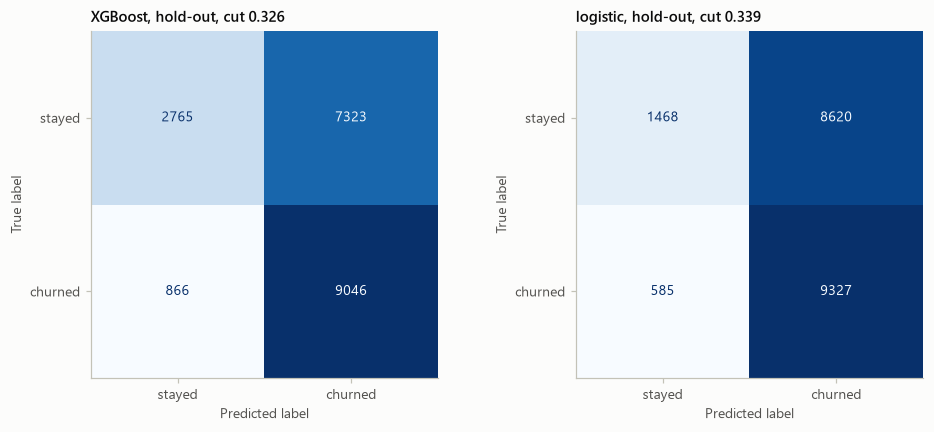

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, p) in zip(axes, proba.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p >= cuts[name], display_labels=["stayed", "churned"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}, hold-out, cut {cuts[name]:.3f}")
fig.tight_layout()

In [9]:
# Campaign view: contact the k% riskiest customers. Precision = share of them who churn, recall = share of all
# churners reached. On this ~50% sample a random list has precision 0.50 and recall k.
def top_share(y_true: np.ndarray, p: np.ndarray, share: float) -> pd.Series:
    picked = p >= np.quantile(p, 1 - share)
    return pd.Series({"precision": y_true[picked].mean(), "recall": y_true[picked].sum() / y_true.sum()})


pd.concat({name: pd.DataFrame({f"top {q:.0%}": top_share(y_test.to_numpy(), p, q) for q in (0.1, 0.2, 0.3, 0.5)})
           for name, p in proba.items()})

top 10%  top 20%  top 30%  top 50%
XGBoost  precision   0.8175   0.7492   0.7065   0.6384
         recall      0.1650   0.3024   0.4277   0.6441
logistic precision   0.7245   0.6775   0.6453   0.6003
         recall      0.1462   0.2734   0.3906   0.6056

**Takeaway:** on the 20,000 hold-out customers XGBoost scores **ROC-AUC 0.704**, PR-AUC 0.696 and log-loss 0.624, within the CV noise (0.705). The tuning on the training folds did not overfit them.
- **XGBoost at its cut (0.326): recall 0.91, precision 0.55, F1 0.69.** It flags 16,369 customers (82%): 9,046 of the 9,912 churners are caught and 866 missed, while 7,323 of the 10,088 stayers are flagged too.
- **Logistic at its cut (0.339): recall 0.94, precision 0.52, F1 0.67**, with 90% flagged. Its higher recall comes from flagging 1,600 more customers, not from a better ranking: ROC-AUC 0.645 against 0.704.
- **Campaign view: among the 10% riskiest customers, 82% churn** (logistic 72%, a random list 50%), and they are 17% of all churners. In the top 20%, 75% churn. That is where the two models differ most, and where a retention budget is spent.

## 7. What drives the predictions: SHAP on the hold-out set
For each customer, TreeSHAP splits the model's log-odds into **one contribution per variable**: base value (the average log-odds) + the sum of the contributions = that customer's log-odds, exactly. XGBoost computes it itself (`pred_contribs=True`, the same algorithm as `shap.TreeExplainer`); the one-hot columns of a categorical are summed into their variable. A variable's **importance is its mean |SHAP|** over the hold-out customers, in log-odds: the same quantity as the logistic regression's mean |contribution|, so the two rankings compare.
- (+) / (−): the Spearman correlation between the variable's value and its SHAP value is at least 0.5 in absolute value, so higher values push one way. No sign: the effect is not monotonic (look at its shape in section 8), or the variable is categorical.
- SHAP explains **the model, not the world**: association, not causation. Near-duplicates share the credit.

base value -0.018 log-odds (p = 0.496); max |base + sum of SHAP - model log-odds| = 6.9e-06


104 input variables; the top 12 carry 50% of the total importance, the top 37 carry 80%
share of the importance by family: {'usage': 0.28999999165534973, 'account': 0.17000000178813934, 'handset': 0.17000000178813934, 'revenue': 0.14000000059604645, 'trend': 0.09000000357627869, 'household': 0.09000000357627869, 'quality': 0.05000000074505806, 'care': 0.009999999776482582}


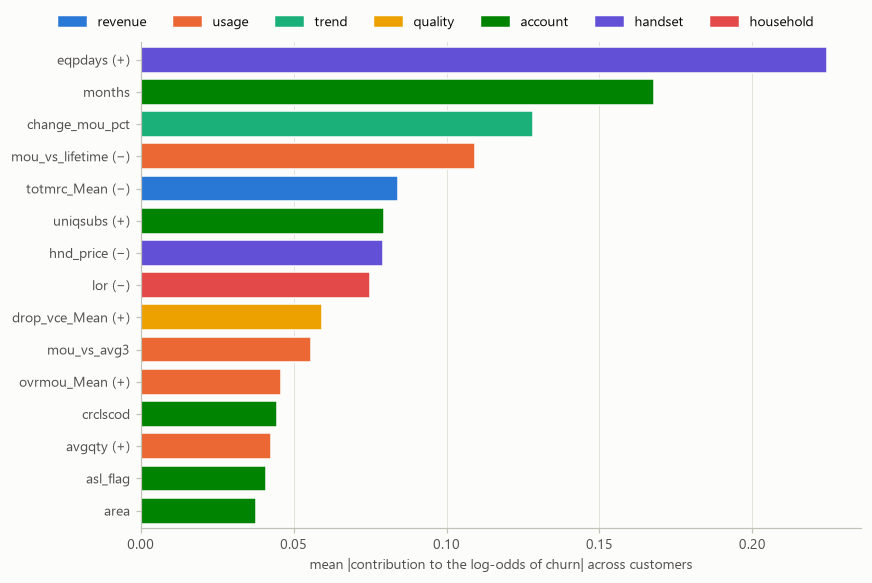

In [10]:
contrib, base = model.tree_contributions(final, X_test)
values = final[:-2].transform(X_test)  # the model's inputs before encoding: cleaned values and the ratios
margin = final[-1].predict(final[:-1].transform(X_test), output_margin=True)
print(f"base value {base:.3f} log-odds (p = {expit(base):.3f}); "
      f"max |base + sum of SHAP - model log-odds| = {np.abs(base + contrib.sum(axis=1) - margin).max():.1e}")
imp = model.shap_importance(contrib, values.select_dtypes("number"), cfg["families"], s["monotonic_rho"])
share = imp["importance"].cumsum() / imp["importance"].sum()
fam = imp.groupby("family")["importance"].sum().sort_values(ascending=False)
print(f"{len(imp)} input variables; the top {int((share < 0.5).sum()) + 1} carry 50% of the total importance, "
      f"the top {int((share < 0.8).sum()) + 1} carry 80%")
print("share of the importance by family:", (fam / fam.sum()).round(2).to_dict())
fig = plots.plot_importance(imp, colors, 15)

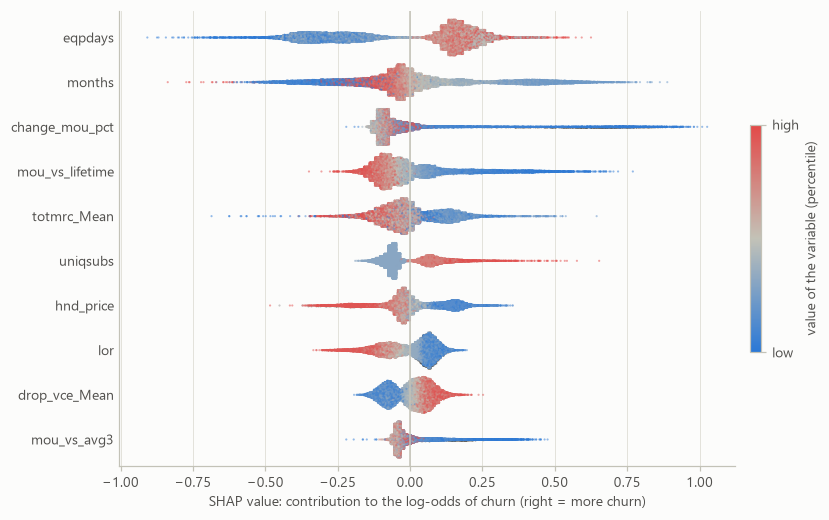

In [11]:
fig = plots.plot_beeswarm(contrib, values, list(imp.index[:10]), cfg["seed"])

**Takeaway: four variables lead**: handset age (`eqpdays`, 0.22 log-odds on average), tenure (`months`, 0.17), the usage change as a share of the customer's own level (`change_mou_pct`, 0.13) and usage against the lifetime average (`mou_vs_lifetime`, 0.11). Then come the plan fee, subscribers, handset price and years at the address (0.075–0.084).
- The additivity check holds: base value + SHAP values rebuild every customer's log-odds within 7·10⁻⁶. The top 12 of 104 variables carry half of the importance, the top 37 carry 80%.
- **The new trend ratios are in the top 10**: `change_mou_pct` 3rd and `mou_vs_avg3` 10th. As a share of the customer's level, the usage drop replaces the raw difference `change_mou`.
- **Families**: usage 29%, account 17%, handset 17%, revenue 14%, trend 9%, household 9%, quality 5%, care 1%.
- **Reading the beeswarm** (red = high value, blue = low):
  - `eqpdays` splits into two clusters, a step (section 8);
  - `months` has no colour order, because its effect is a peak;
  - large usage drops (blue) push far right in `change_mou_pct`, `mou_vs_lifetime` and `mou_vs_avg3`;
  - more subscribers and more dropped calls push right;
  - a dearer handset, a longer residence and a higher plan fee push left.

## 8. The shape of the main effects
A dependence plot puts each hold-out customer at (value of the variable, its SHAP value): the curve the model has learned, with every other variable at the customer's own value. One panel for each of the 6 most important numeric variables, on a shared y axis so the sizes compare; the black line is the mean SHAP per value (or per quantile bin). In odds terms, +0.5 log-odds ≈ ×1.65 the odds and +1 ≈ ×2.7, for the same customer otherwise.

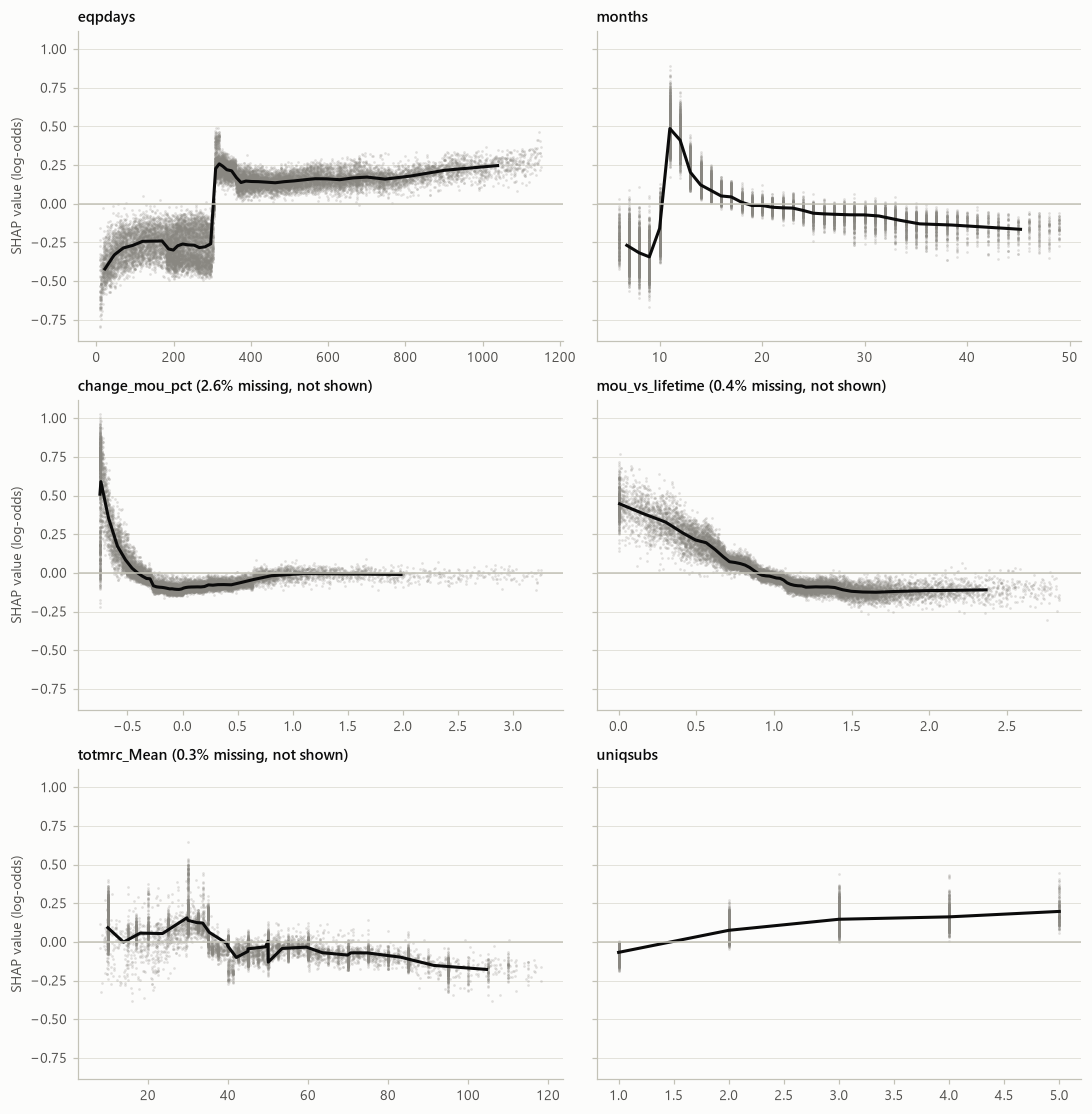

In [12]:
numeric = [v for v in imp.index if v in values.select_dtypes("number")]
fig = plots.plot_dependence(contrib, values, numeric[:6])

In [13]:
# The two shapes the recommendations rest on, in numbers: mean SHAP per month of tenure and per band of handset age,
# next to the observed hold-out churn rate.
def by_band(col: str, bands) -> pd.DataFrame:
    g = pd.DataFrame({"mean_shap": contrib[col], "churn_rate": y_test}).groupby(bands, observed=True)
    return g.mean().assign(customers=g.size()).T


display(by_band("months", values["months"].where(values["months"] <= 24)).rename_axis("months", axis=1))
by_band("eqpdays", pd.cut(values["eqpdays"], s["bands"]["eqpdays"], right=False)).rename_axis("eqpdays", axis=1)

months,6.0000,7.0000,8.0000,9.0000,10.0000,11.0000,12.0000,13.0000,14.0000,15.0000,16.0000,17.0000,18.0000,19.0000,20.0000,21.0000,22.0000,23.0000,24.0000
mean_shap,-0.2312,-0.2777,-0.3168,-0.3431,-0.1597,0.4866,0.4116,0.2041,0.1223,0.0867,0.0507,0.0444,0.0101,-0.0110,-0.0110,-0.0223,-0.0259,-0.0277,-0.0429
churn_rate,0.3790,0.3461,0.3014,0.2935,0.3986,0.6634,0.6249,0.5504,0.5414,0.5273,0.5028,0.5113,0.4992,0.4867,0.5158,0.4986,0.5109,0.5089,0.5215
customers,248.0000,994.0000,720.0000,811.0000,828.0000,1622.0000,1189.0000,1161.0000,918.0000,751.0000,722.0000,710.0000,639.0000,787.0000,568.0000,724.0000,550.0000,727.0000,466.0000


eqpdays,"[0, 240)","[240, 270)","[270, 300)","[300, 330)","[330, 360)","[360, 420)","[420, 600)","[600, 2000)"
mean_shap,-0.2959,-0.2737,-0.2789,0.2099,0.2192,0.1449,0.1482,0.1936
churn_rate,0.4023,0.3690,0.3917,0.5933,0.6425,0.5509,0.5282,0.5564
customers,5906.0000,1019.0000,1016.0000,1473.0000,1239.0000,2071.0000,3453.0000,3823.0000


**Takeaway: the effects are steps, peaks and plateaus, which is why XGBoost beats the linear model.** In odds terms, +0.5 log-odds ≈ ×1.65.
- **Handset age is a step at 300 days.** −0.27 to −0.30 below 300 days, +0.21 / +0.22 at 300–360, then about +0.15 rising slowly to +0.25 at 1,000 days. The step is about +0.5 log-odds (odds ×1.6), and hold-out churn goes from 37–40% to 59–64%.
- **Tenure is a peak at 11–12 months.** −0.32 / −0.34 at 8–9 months, −0.16 at 10, **+0.49 at 11**, +0.41 at 12, +0.20 at 13, about 0 from 18 months. Month 9 → 11 is +0.83 log-odds (odds ×2.3); hold-out churn goes from 29% to 66%.
- **Usage change as a share of own level: the risk is in the drops.** A 75% drop adds about +0.6 (up to +1.0). The effect falls to 0 at a drop of about 30%, and stable or growing usage is slightly protective (−0.1).
- **Usage against the lifetime average** is a slope that ends in a plateau: +0.45 at zero usage, 0 at about 90% of the usual, flat (−0.1) above it.
- **Plan fee** is a bump: $20–35 plans add up to +0.15, plans of $40 or more protect (down to −0.17 at $100).
- **Subscribers**: 1 = −0.06, 2 = +0.08, 3 = +0.15, 5 = +0.20.

## 9. One customer at a time
The waterfall starts from the model's average log-odds and adds one bar per variable, the 10 largest first and the rest summed, until it reaches the customer's own log-odds. Two hold-out customers: one at the 99th percentile of predicted risk and one at the median. No identifier is shown.

high-risk customer: p = 0.90, churned: True


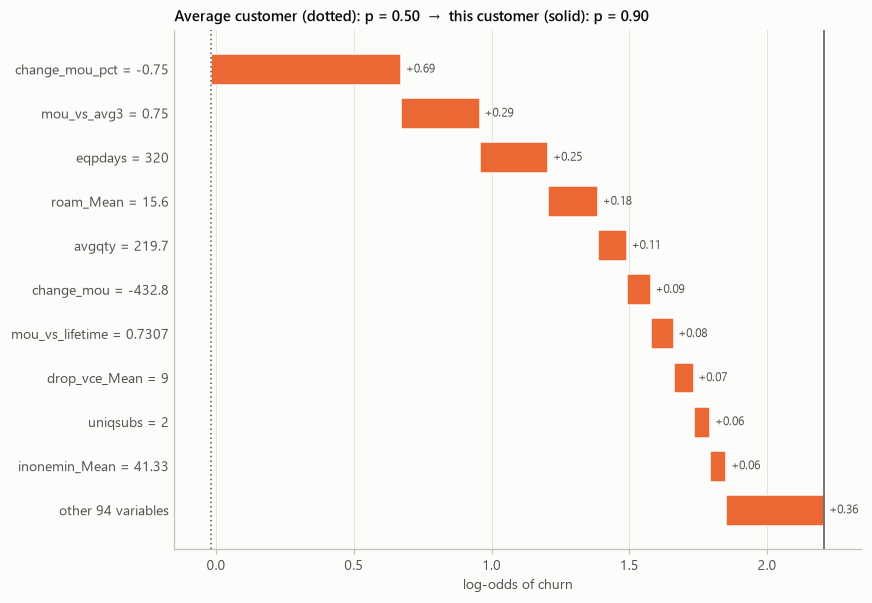

In [14]:
p = pd.Series(proba["XGBoost"], index=X_test.index)
high, typical = (p - p.quantile(0.99)).abs().idxmin(), (p - p.median()).abs().idxmin()
print(f"high-risk customer: p = {p[high]:.2f}, churned: {bool(y_test[high])}")
fig = plots.plot_waterfall(contrib.loc[high], values.loc[high], base)

typical customer: p = 0.50, churned: False


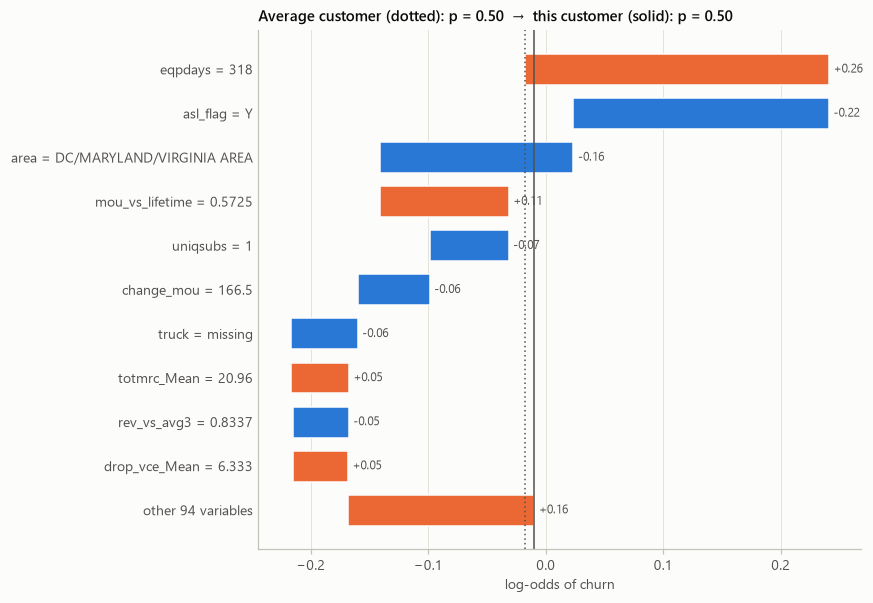

In [15]:
print(f"typical customer: p = {p[typical]:.2f}, churned: {bool(y_test[typical])}")
fig = plots.plot_waterfall(contrib.loc[typical], values.loc[typical], base)

In [16]:
# How common is the top-risk profile? Hold-out customers with zero minutes this month.
zero = values["mou_Mean"] == 0
pd.Series({"share of customers": zero.mean(), "churn rate": y_test[zero].mean(),
           "share of the riskiest 1%": zero[p >= p.quantile(0.99)].mean(),
           "share of the riskiest 10%": zero[p >= p.quantile(0.9)].mean()})

share of customers          0.0163
churn rate                  0.8221
share of the riskiest 1%    0.2450
share of the riskiest 10%   0.1260
dtype: float64

**Takeaway: the waterfall turns a score into a reason, and the reason decides the action.**
- **High-risk customer (p = 0.90, churned): usage is collapsing.**
  - The last month is 75% below the 3-month average (`change_mou_pct`, +0.69), and the mean usage is 25% below it (`mou_vs_avg3`, +0.29).
  - The handset is 320 days old, just past the step (+0.25).
  - Roaming calls add +0.18.
- **Typical customer (p = 0.50, stayed): signals that cancel out.**
  - A 318-day handset, just past the step (+0.26), is offset by a spending limit (`asl_flag`, −0.22) and the DC/Maryland/Virginia area (−0.16); everything else is small.
  - If this customer were contacted, the lever would be a handset upgrade.
- **Zero usage this month** concerns 1.6% of customers, 82% of whom churn. These customers are now 25% of the riskiest 1% (42% in the previous version) and 13% of the riskiest 10%. With the trend ratios, the top of the list holds more customers whose usage is falling but not yet zero, which is where a retention call still has a chance.

## 10. How stable is the ranking?
A tree model has no p-values. The honest version of "this variable is significant" is: **does it stay at the top when the training customers change?** The tuned pipeline is refitted on each CV training split and its mean |SHAP| measured on the corresponding validation fold (training set only).

In [17]:
fold_imp = model.fold_importance(model.build_tree_pipeline(cfg, model.xgboost(cfg, **best)), X, y, cfg)
ranks = fold_imp.rank(ascending=False)
print("Spearman correlation of each fold's ranking with the hold-out ranking (all variables):",
      fold_imp.corrwith(imp["importance"], method="spearman").round(3).to_dict())
lead = imp.index[:12]
pd.DataFrame({"hold-out rank": np.arange(1, 13), "fold rank min": ranks.loc[lead].min(axis=1),
              "fold rank max": ranks.loc[lead].max(axis=1), "hold-out importance": imp.loc[lead, "importance"],
              "fold importance CV": fold_imp.loc[lead].std(axis=1) / fold_imp.loc[lead].mean(axis=1)})

Spearman correlation of each fold's ranking with the hold-out ranking (all variables): {'fold 1': 0.987, 'fold 2': 0.986, 'fold 3': 0.986, 'fold 4': 0.987, 'fold 5': 0.986}


,hold-out rank,fold rank min,fold rank max,hold-out importance,fold importance CV
eqpdays,1,1.0000,1.0000,0.2244,0.0145
months,2,2.0000,2.0000,0.1680,0.0117
change_mou_pct,3,3.0000,3.0000,0.1282,0.0398
mou_vs_lifetime,4,4.0000,4.0000,0.1093,0.0477
totmrc_Mean,5,5.0000,6.0000,0.0841,0.0385
uniqsubs,6,5.0000,7.0000,0.0794,0.0550
hnd_price,7,6.0000,8.0000,0.0792,0.0651
lor,8,6.0000,8.0000,0.0751,0.0501
drop_vce_Mean,9,9.0000,10.0000,0.0591,0.0855
mou_vs_avg3,10,9.0000,10.0000,0.0556,0.0803


**Takeaway: the ranking is stable.** Each fold's ranking of all 104 variables correlates 0.986–0.987 (Spearman) with the hold-out ranking.
- **The top 4 never move**: `eqpdays` 1st, `months` 2nd, `change_mou_pct` 3rd, `mou_vs_lifetime` 4th in every fold.
- Positions 5–10 move by at most 2 places, with an importance that varies 4–9% across folds.
- From 11th place the order is noise (`ovrmou_Mean` 11th–16th, `crclscod` 11th–14th): read those as moderate effects, not by position. The honest "significant drivers" are the top 10.

## Conclusions

**Results** (5-fold CV on the training set; hold-out scored once)
1. The **trend ratios** add +0.0067 ± 0.0005 ROC-AUC. The **Bayesian search** (Optuna TPE, 40 trials, CV log-loss) adds +0.0023 ± 0.0005. The final model: depth 8, 913 trees, learning rate 0.014, `min_child_weight` 5, `subsample` 0.88, `colsample_bytree` 0.69.
2. **ROC-AUC 0.705 in CV and 0.704 on the hold-out**, +0.061 over the logistic regression.
3. At the F1-best cut (0.326), on the hold-out: **recall 0.91, precision 0.55, F1 0.69**, with 82% of customers flagged (logistic: recall 0.94, precision 0.52, F1 0.67, 90% flagged). **Among the 10% riskiest, 82% churn** (logistic 72%, random 50%).
4. The importance ranking is stable across folds (Spearman 0.99); the top 4 never move.

**What drives churn** (SHAP on the hold-out; association, not causation)
1. **Handset age past 300 days**: a step, odds ×1.6.
2. **Tenure of 11–12 months**: a peak, odds ×2.3 at month 11 against month 9.
3. **Usage falling below the customer's own level**: more than ~30% below the last three months, and below ~90% of the lifetime average.
4. **Entry-level plans ($20–35), cheap handsets, a short time at the address, more subscribers in the household, dropped calls.**

**What this suggests for retention**
- **Handset upgrade offer before day 300.**
- **Renewal contact at month 9–10**, before the peak.
- **Usage-drop trigger**: flag customers whose usage falls more than ~30% below their own 3-month average, before it reaches zero.
- **Network-quality follow-up** for customers with dropped calls.
- The model says **who** is at risk and **why**, not **what works**: a pilot with a control group is needed to measure each action.

**Limits**
- SHAP explains the model, not the world, and near-duplicates share the credit.
- Probabilities and precision are on the ~50% sample.
- Zero usage may be measured after the decision to leave (the open observation-date question).
- The F1-best cut flags 82% of customers. In a real campaign the cut is set by the budget (the top-k table).